# - Task: Exploratory data analysis plus a linear regression, with the data and the fitted line on one plot
- Tone: direct, simple, concise
- Target: a jupyter notebook I can run top to bottom: one figure with the scatter and the fitted line, plus printed MAE and R2
- Traits: experienced software developer and data analyst

Read the attached CSV with pandas. Explore it: shape, describe(), missing values. Then fit a simple linear regression of Revenue on Temperature with scikit-learn, plot the data and the fitted line on one figure, and print the coefficients, the intercept, MAE and R2.


In [1]:
# Make the paths below work whichever folder this notebook is opened from.
import os
import pathlib

root = pathlib.Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
print("working directory:", pathlib.Path.cwd())


working directory: c:\Users\novij\Desktop\Pba Softwareudvikling\2. Semester\LLMs for udviklere\project\LLM-group-a\exam_project


Shape of the data: (500, 2)
Description of the data:
        Temperature      Revenue
count   500.000000   500.000000
mean     22.232225   521.570777
std       8.096388   175.404751
min       0.000000    10.000000
25%      17.122258   405.558681
50%      22.392791   529.368565
75%      27.740674   642.257922
max      45.000000  1000.000000
Missing values:
 Temperature    0
Revenue        0
dtype: int64


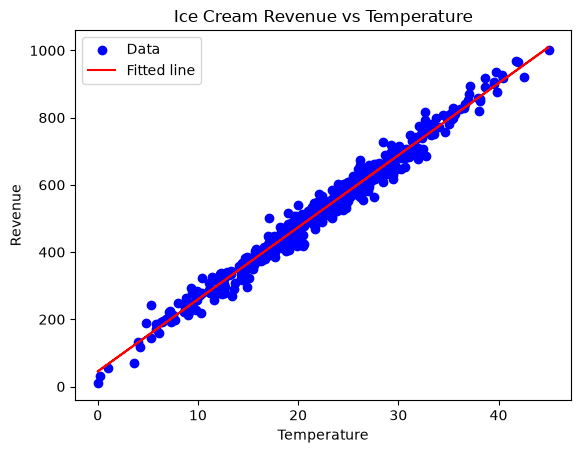

Coefficients: [[21.44362551]]
Intercept: [44.83126709]
MAE: 19.585861206200104
R2: 0.979707200117581


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Read the data
data = pd.read_csv(r'C:\Users\novij\Desktop\Pba Softwareudvikling\2. Semester\LLMs for udviklere\project\LLM-group-a\exam_project\regression\runs\rag\ui\9\ice_cream_regression.csv')

# Explore the data
print("Shape of the data:", data.shape)
print("Description of the data:\n", data.describe())
print("Missing values:\n", data.isnull().sum())

# Fit a simple linear regression
X = data['Temperature'].values.reshape(-1, 1)
y = data['Revenue'].values.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y)

# Predict and calculate metrics
y_pred = model.predict(X)
mae = mean_absolute_error(y, y_pred)
r2 = r2_score(y, y_pred)

# Plot the data and the fitted line
plt.scatter(X, y, color='blue', label='Data')
plt.plot(X, y_pred, color='red', label='Fitted line')
plt.xlabel('Temperature')
plt.ylabel('Revenue')
plt.title('Ice Cream Revenue vs Temperature')
plt.legend()
plt.show()

# Print the coefficients, intercept, MAE, and R2
print(f"Coefficients: {model.coef_}")
print(f"Intercept: {model.intercept_}")
print(f"MAE: {mae}")
print(f"R2: {r2}")